# CEDA UK to `Geocroissant` Support
<img src="../assets/geocr.jpg" alt="GeoCroissant" width="150" style="float: right; margin-left: 50px;">

## Overview

This notebook demonstrates how to convert CEDA UK STAC (SpatioTemporal Asset Catalog) metadata to GeoCroissant format, which is an extension of the Croissant metadata standard for geospatial datasets.

# Install dependencies

In [1]:
# Install dependencies
try:
    from ceda_datapoint import DataPointClient
except ImportError as exc:
    !pip install ceda-datapoint
    from ceda_datapoint import DataPointClient

# Create a client instance - for searching the CEDA STAC catalog

In [2]:
from ceda_datapoint import DataPointClient

client = DataPointClient(org="CEDA")
client


<DataPointClient: CEDA-548809>
 - url: https://api.stac.ceda.ac.uk
 - organisation: CEDA

# Basic search
Perform a basic search of the CMIP6 climate model simulations dataset, filtering on experiment, activity and institution:

In [3]:
search_basic = client.search(
    collections=["cmip6"],
    query=[
        "cmip6:experiment_id=ssp585",
        "cmip6:activity_id=ScenarioMIP",
        "cmip6:institution_id=KIOST",
    ],
    max_items=10,
)

# Collect up the "cloud assets" connected with the search results
This method collects up the cloud assets, which may be Zarr, NetCDF or Kerchunk files. The latter represent an index that points to content within other files (typically NetCDF).

The files themselves can be served over a variety of protocols, including:

POSIX: local file system
HTTP(S): old-fashioned HTTP(S) access
S3: using Amazon's S3 protocol (over HTTP(S))
We identify them and then list the related products.

In [4]:
cluster = search_basic.collect_cloud_assets()
cluster


<DataPointCluster: CEDA-548809-252256-200510 (Datasets: 10)>
 - url: https://api.stac.ceda.ac.uk
 - organisation: CEDA
 - search_terms: {'query': ['cmip6:experiment_id=ssp585', 'cmip6:activity_id=ScenarioMIP', 'cmip6:institution_id=KIOST'], 'max_items': 10}
 - collections: ['cmip6']
 - products: 10
Products:
 - CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.vas.gr1.v20191106-reference_file: kerchunk
 - CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.uas.gr1.v20210319-reference_file: kerchunk
 - CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106-reference_file: kerchunk
 - CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.sfcWind.gr1.v20191106-reference_file: kerchunk
 - CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.rsus.gr1.v20191106-reference_file: kerchunk
 - CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.rsds.gr1.v20191106-reference_file: kerchunk
 - CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.rlus.gr1.v20191106-

In [5]:
product = cluster[2]
ds = product.open_dataset()

In [6]:
dir(product)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__slots__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_mapper',
 '_multiple_options',
 '_open_cfa',
 '_open_cog',
 '_open_kerchunk',
 '_open_zarr',
 '_prepare_dataset',
 '_set_visibility',
 'attributes',
 'bbox',
 'cloud_format',
 'collection',
 'end_datetime',
 'get_attribute',
 'help',
 'href',
 'id',
 'info',
 'meta',
 'open_asset',
 'open_dataset',
 'stac_attributes',
 'start_datetime',
 'units',
 'variables']

# Select a product and use it (as an Xarray Dataset)
A product has an .open_dataset() method, which loads it (lazily) into an xarray.Dataset, making it ready for use in the Python session.

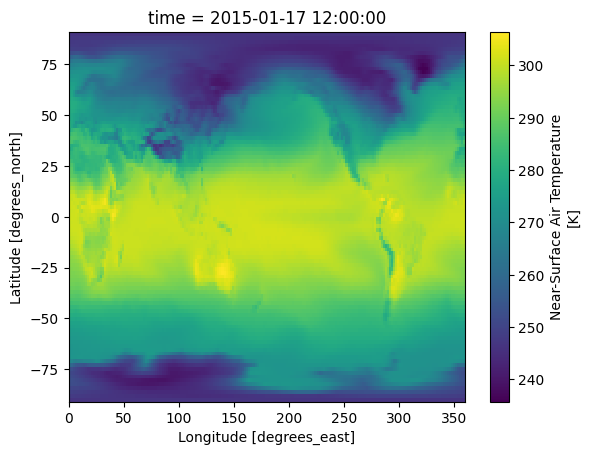

In [7]:
tas_product = None

for product in cluster:
    if "tas" in product.id:
        tas_product = product
        break

if tas_product:
    ds = tas_product.open_dataset()
    ds.tas.sel(time="2015-01-17 12:00:00").squeeze().plot()
else:
    print("tas variable not found in cluster")

In [8]:
for product in cluster:
    if "tas" in product.id:
        print(product.id)
        print(product.stac_attributes.keys())
        print(product.stac_attributes)
        break

CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106-reference_file
dict_keys(['type', 'stac_version', 'stac_extensions', 'id', 'geometry', 'bbox', 'links', 'collection'])
{'type': 'Feature', 'stac_version': '1.1.0', 'stac_extensions': ['https://stac-extensions.github.io/cmip6/v1.0.0/schema.json'], 'id': 'CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106', 'geometry': {'coordinates': [[[-179.0625, -90.0], [179.0625, -90.0], [179.0625, 90.0], [-179.0625, 90.0], [-179.0625, -90.0]]], 'type': 'Polygon'}, 'bbox': [-179.0625, -90.0, 179.0625, 90.0], 'links': [{'rel': 'self', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6/items/CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106', 'type': 'application/geo+json'}, {'rel': 'parent', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6', 'type': 'application/json'}, {'rel': 'collection', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6', 'type': 'application/json', 

In [9]:
for product in cluster:
    print(f"\nProduct ID: {product.id}")
    print("Available stac_attributes keys:", product.stac_attributes.keys())


Product ID: CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.vas.gr1.v20191106-reference_file
Available stac_attributes keys: dict_keys(['type', 'stac_version', 'stac_extensions', 'id', 'geometry', 'bbox', 'links', 'collection'])

Product ID: CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.uas.gr1.v20210319-reference_file
Available stac_attributes keys: dict_keys(['type', 'stac_version', 'stac_extensions', 'id', 'geometry', 'bbox', 'links', 'collection'])

Product ID: CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106-reference_file
Available stac_attributes keys: dict_keys(['type', 'stac_version', 'stac_extensions', 'id', 'geometry', 'bbox', 'links', 'collection'])

Product ID: CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.sfcWind.gr1.v20191106-reference_file
Available stac_attributes keys: dict_keys(['type', 'stac_version', 'stac_extensions', 'id', 'geometry', 'bbox', 'links', 'collection'])

Product ID: CMIP6.ScenarioMIP.KIOST.KIOST-ESM.s

In [10]:
tas_products = [p for p in cluster if "tas" in p.id]

for p in tas_products:
    print(p.id)

CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106-reference_file


In [11]:
# Access metadata for the selected 'tas' product
if tas_product:
    metadata = tas_product.stac_attributes
    print("STAC Metadata for Product ID:", tas_product.id)
    print("STAC Attributes:", metadata)

    # If you'd like to see more details or other attributes:
    for key, value in metadata.items():
        print(f"{key}: {value}")
else:
    print("tas product not found.")

STAC Metadata for Product ID: CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106-reference_file
STAC Attributes: {'type': 'Feature', 'stac_version': '1.1.0', 'stac_extensions': ['https://stac-extensions.github.io/cmip6/v1.0.0/schema.json'], 'id': 'CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106', 'geometry': {'coordinates': [[[-179.0625, -90.0], [179.0625, -90.0], [179.0625, 90.0], [-179.0625, 90.0], [-179.0625, -90.0]]], 'type': 'Polygon'}, 'bbox': [-179.0625, -90.0, 179.0625, 90.0], 'links': [{'rel': 'self', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6/items/CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106', 'type': 'application/geo+json'}, {'rel': 'parent', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6', 'type': 'application/json'}, {'rel': 'collection', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6', 'type': 'application/json', 'title': 'CMIP6'}, {'rel': 'root', 'href': 'https://api.s

In [12]:
if tas_product:
    # Extract STAC metadata fields
    metadata = tas_product.stac_attributes
    item_metadata = {
        "ID": tas_product.id,
        "Type": metadata.get("type"),
        "STAC Version": metadata.get("stac_version"),
        "Collection": metadata.get("collection"),
        "Links": metadata.get("links"),
        "Bounding Box": metadata.get("bbox"),
        "Geometry": metadata.get("geometry"),
    }

    # Display metadata
    for key, value in item_metadata.items():
        print(f"{key}: {value}")
else:
    print("tas product not found.")

ID: CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106-reference_file
Type: Feature
STAC Version: 1.1.0
Collection: cmip6
Links: [{'rel': 'self', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6/items/CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106', 'type': 'application/geo+json'}, {'rel': 'parent', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6', 'type': 'application/json'}, {'rel': 'collection', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6', 'type': 'application/json', 'title': 'CMIP6'}, {'rel': 'root', 'href': 'https://api.stac.ceda.ac.uk', 'type': 'application/json', 'title': 'CEDA STAC API'}]
Bounding Box: [-179.0625, -90.0, 179.0625, 90.0]
Geometry: {'coordinates': [[[-179.0625, -90.0], [179.0625, -90.0], [179.0625, 90.0], [-179.0625, 90.0], [-179.0625, -90.0]]], 'type': 'Polygon'}


In [13]:
print(dir(tas_product))

['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__slots__', '__str__', '__subclasshook__', '__weakref__', '_mapper', '_multiple_options', '_open_cfa', '_open_cog', '_open_kerchunk', '_open_zarr', '_prepare_dataset', '_set_visibility', 'attributes', 'bbox', 'cloud_format', 'collection', 'end_datetime', 'get_attribute', 'help', 'href', 'id', 'info', 'meta', 'open_asset', 'open_dataset', 'stac_attributes', 'start_datetime', 'units', 'variables']


# Inspecting Metadata in a STAC Item

In [14]:
# Try checking the 'variables' attribute to see if the data is present there
print(tas_product.variables)

# Or inspect the 'stac_attributes' for any relevant metadata
print(tas_product.stac_attributes)

# You can also explore 'attributes' if the other two don't help
print(tas_product.attributes)

WARNING [ceda_datapoint.mixins.properties]: Attribute not found from options: ['variables', 'variable_long_name']


None
{'type': 'Feature', 'stac_version': '1.1.0', 'stac_extensions': ['https://stac-extensions.github.io/cmip6/v1.0.0/schema.json'], 'id': 'CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106', 'geometry': {'coordinates': [[[-179.0625, -90.0], [179.0625, -90.0], [179.0625, 90.0], [-179.0625, 90.0], [-179.0625, -90.0]]], 'type': 'Polygon'}, 'bbox': [-179.0625, -90.0, 179.0625, 90.0], 'links': [{'rel': 'self', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6/items/CMIP6.ScenarioMIP.KIOST.KIOST-ESM.ssp585.r1i1p1f1.Amon.tas.gr1.v20191106', 'type': 'application/geo+json'}, {'rel': 'parent', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6', 'type': 'application/json'}, {'rel': 'collection', 'href': 'https://api.stac.ceda.ac.uk/collections/cmip6', 'type': 'application/json', 'title': 'CMIP6'}, {'rel': 'root', 'href': 'https://api.stac.ceda.ac.uk', 'type': 'application/json', 'title': 'CEDA STAC API'}], 'collection': 'cmip6'}
{'cmip6:further_info_url': 'https:

# CMIP6 STAC to GeoCroissant Converter

This section curates GeoCroissant metadata for the selected CEDA STAC item

In [15]:
import json
import mlcroissant as mlc

# Extract STAC item and attributes dynamically from tas_product and ds
stac_item = search_basic.items[tas_product.meta["item"]]
attrs = tas_product.attributes
stac_attrs = tas_product.stac_attributes
bbox = tas_product.bbox
item_url = next(
    (l["href"] for l in stac_attrs.get("links", []) if l.get("rel") == "self"),
    tas_product.href,
)

var_id = attrs.get("cmip6:variable_id", "tas")
var_long_name = attrs.get("cmip6:variable_long_name", "Near-Surface Air Temperature")
source_id = attrs.get("cmip6:source_id", "KIOST-ESM")
exp_id = attrs.get("cmip6:experiment_id", "ssp585")
act_id = attrs.get("cmip6:activity_id", "ScenarioMIP")
units = attrs.get("cmip6:variable_units", "K")
res_val = int(attrs.get("cmip6:nominal_resolution", "250 km").split()[0])

ctx = mlc.Context(
    is_live_dataset=True,
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/RAI/",
        "http://mlcommons.org/croissant/geo/",
    ],
)

# 1. Define FileObjects dynamically from the STAC item assets
distribution = []
for asset_key, asset in stac_item._assets.items():
    href = asset.href
    if not href:
        continue
    file_id = f"tas-{asset_key}"
    file_name = href.split("/")[-1]

    if href.endswith(".json"):
        enc = "application/json"
        desc = f"Kerchunk virtual reference index for {stac_item.id}"
    elif href.endswith((".nc", ".nc4")):
        enc = "application/x-netcdf"
        desc = f"NetCDF multidimensional data array for {stac_item.id}"
    elif href.endswith((".jpg", ".png")):
        enc = "image/jpeg" if href.endswith(".jpg") else "image/png"
        desc = f"Preview thumbnail image for {stac_item.id}"
    else:
        enc = "application/octet-stream"
        desc = f"Asset {asset_key} for {stac_item.id}"

    distribution.append(
        mlc.FileObject(
            ctx=ctx,
            id=file_id,
            name=file_name,
            description=desc,
            content_url=href,
            encoding_formats=[enc],
        )
    )

# Primary NetCDF file object ID for record extraction
primary_file_id = next(
    (fo.id for fo in distribution if "application/x-netcdf" in fo.encoding_formats),
    distribution[0].id,
)

# 2. Define RecordSets dynamically from opened dataset (ds)
tas_shape = ",".join(str(s) for s in ds.tas.shape)
time_shape = str(len(ds.time))
lat_shape = str(len(ds.lat))
lon_shape = str(len(ds.lon))

record_sets = [
    mlc.RecordSet(
        ctx=ctx,
        id="tas_dataset",
        name="Near-Surface Air Temperature (tas) Dataset",
        description=f"{var_long_name} from {source_id} model",
        spatial_resolution=mlc.QuantitativeValue(value=res_val, unitText="km"),
        temporal_resolution=mlc.QuantitativeValue(value=1, unitText="month"),
        fields=[
            mlc.Field(
                ctx=ctx,
                id="tas_dataset/time",
                name="time",
                description="Time coordinate",
                data_types=[mlc.DataType.DATE],
                is_array=True,
                array_shape=time_shape,
                source=mlc.Source(
                    ctx=ctx,
                    file_object=primary_file_id,
                    extract=mlc.Extract(column="time"),
                ),
            ),
            mlc.Field(
                ctx=ctx,
                id="tas_dataset/latitude",
                name="latitude",
                description="Latitude coordinate",
                data_types=[mlc.DataType.FLOAT],
                is_array=True,
                array_shape=lat_shape,
                source=mlc.Source(
                    ctx=ctx,
                    file_object=primary_file_id,
                    extract=mlc.Extract(column="lat"),
                ),
            ),
            mlc.Field(
                ctx=ctx,
                id="tas_dataset/longitude",
                name="longitude",
                description="Longitude coordinate",
                data_types=[mlc.DataType.FLOAT],
                is_array=True,
                array_shape=lon_shape,
                source=mlc.Source(
                    ctx=ctx,
                    file_object=primary_file_id,
                    extract=mlc.Extract(column="lon"),
                ),
            ),
            mlc.Field(
                ctx=ctx,
                id="tas_dataset/tas",
                name="tas",
                description=f"{var_long_name} in {units}",
                data_types=[mlc.DataType.FLOAT],
                is_array=True,
                array_shape=tas_shape,
                source=mlc.Source(
                    ctx=ctx,
                    file_object=primary_file_id,
                    extract=mlc.Extract(column="tas"),
                ),
            ),
        ],
    ),
]

# 3. Create core metadata with GeoCroissant & RAI attributes
metadata = mlc.Metadata(
    ctx=ctx,
    name=f"cmip6-{source_id.lower()}-{exp_id.lower()}-tas",
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/RAI/",
        "http://mlcommons.org/croissant/geo/",
    ],
    description=(
        f"{var_long_name} ({var_id}) "
        f"climate simulation from {source_id} under CMIP6 {act_id} {exp_id} scenario."
    ),
    url=item_url,
    cite_as="""@article{Eyring_2016,
    author = {Eyring, Veronika and Bony, Sandrine and Meehl, Gerald A. and et al.},
    doi    = {10.5194/gmd-9-1937-2016},
    journal = {Geoscientific Model Development},
    pages  = {1937--1958},
    title  = {{Overview of the Coupled Model Intercomparison Project Phase 6 (CMIP6)}},
    volume = {9},
    year   = {2016}}""",
    date_published=str(attrs.get("created", "2025-01-24"))[:10],
    version="1.0.0",
    license=(
        "https://artefacts.ceda.ac.uk/licences/specific_licences/CMIP6_Terms_of_Use.pdf"
    ),
    keywords=[
        "CMIP6",
        "CEDA",
        "climate simulation",
        source_id,
        exp_id,
        var_id,
        attrs.get("cmip6:cf_standard_name", "air_temperature"),
        "netcdf",
        "kerchunk",
    ],
    creators=[
        mlc.Organization(name="Centre for Environmental Data Analysis (CEDA)"),
        mlc.Organization(name=attrs.get("cmip6:institution_id", "KIOST")),
    ],
    # GeoCroissant properties
    coordinate_reference_system="EPSG:4326",
    record_endpoint=tas_product.meta.get("url", "https://api.stac.ceda.ac.uk"),
    spatial_resolution=mlc.QuantitativeValue(value=res_val, unitText="km"),
    temporal_resolution=mlc.QuantitativeValue(value=1, unitText="month"),
    spatial_coverage={
        "@type": "Place",
        "geo": {
            "@type": "GeoShape",
            "box": f"{bbox[1]} {bbox[0]} {bbox[3]} {bbox[2]}",
        },
    },
    distribution=distribution,
    record_sets=record_sets,
    extra_properties={
        "temporalCoverage": f"{tas_product.start_datetime}/{tas_product.end_datetime}",
    },
)

# 4. Serialize to JSON-LD
OUTPUT_PATH = "cmip6_tas_geocroissant.json"
with open(OUTPUT_PATH, "w") as f:
    json.dump(metadata.to_json(), f, indent=2)

print(f"GeoCroissant metadata instantiated and written to: {OUTPUT_PATH}")
print(f"Distribution FileObjects: {len(metadata.distribution)}")
print(f"RecordSets defined: {[rs.id for rs in metadata.record_sets]}")

GeoCroissant metadata instantiated and written to: cmip6_tas_geocroissant.json
Distribution FileObjects: 3
RecordSets defined: ['tas_dataset']


In [16]:
!mlcroissant validate --jsonld=cmip6_tas_geocroissant.json

I1107 02:28:04.043100 124790606137152 validate.py:53] Done.


## Load the dataset and visualize

Load the curated GeoCroissant dataset using `mlcroissant.Dataset`, inspect the parsed metadata, and plot the selected climate variable slice.

Dataset name: cmip6-kiost-esm-ssp585-tas
FileObjects in distribution: 3
RecordSets: ['Near-Surface Air Temperature (tas) Dataset']


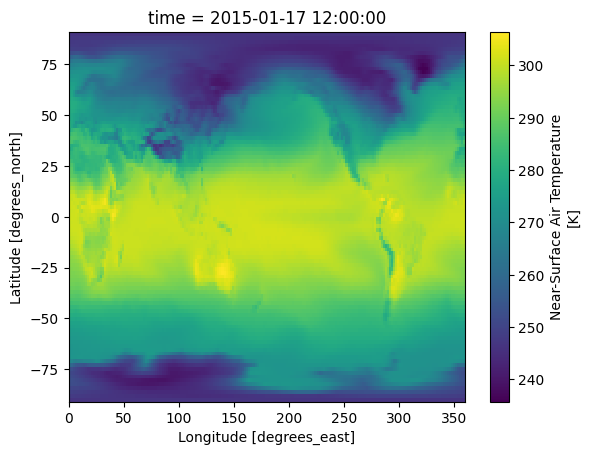

In [17]:
import mlcroissant as mlc
import matplotlib.pyplot as plt

# 5. Load using mlcroissant
dataset = mlc.Dataset("cmip6_tas_geocroissant.json")
meta = dataset.metadata

print("Dataset name:", meta.name)
print("FileObjects in distribution:", len(meta.distribution))
print("RecordSets:", [rs.name for rs in meta.record_sets])

# Visualize Near-Surface Air Temperature (tas) with default Xarray plot
if "ds" in locals() and "tas" in ds:
    ds.tas.sel(time="2015-01-17 12:00:00").squeeze().plot()
    plt.show()